**CNN Model**



*  CNN (Convolutional Neural Network): Extracts spatial patterns from time-series sensor data.
*   Used for disease classification

**Workflow**



*  Load each task data
*  split data to train and test set
*   Normalize each set to prevent data leakage
*   Reshape data sets
*   train model with each task data










In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D , MaxPooling1D, LSTM , Dense , Dropout, Flatten , BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix , classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#ignore warnings

import warnings
warnings.filterwarnings('ignore')
import keras  #used to build CNN

In [17]:
#load extracted features

df = pd.read_csv('Clean_Dataset.csv')

df.head(5)



,Time,Accel_X,Accel_Y,Accel_Z,Gyro_X,Gyro_Y,Gyro_Z,Patient_id,Task,Device location,Height,Weight,Gender,Condition,Age_At_Diagnosis,Handedness,Normalized_Time
0,0.009805,0.002275,0.013380,0.005852,-0.014924,-0.025833,0.004746,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.000393
1,0.019807,0.001332,0.016225,0.005543,-0.009529,-0.033264,0.005853,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.055648
2,0.029791,0.001354,0.018107,0.007207,-0.007440,-0.029995,0.009008,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.110804
3,0.039801,0.001441,0.016004,0.004999,-0.011757,-0.027815,0.017495,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.166104
4,0.052410,0.000535,0.015800,0.005716,-0.013891,-0.029924,0.022822,1,CrossArms,LeftWrist,173,78,0,0,56,0,0.235761


In [18]:
df['Condition'].value_counts()  #healthy:0 and parkinsons:1

,count
Condition,
1,105886
0,29278


In [19]:
#Encode categorical variables

label_encoders = {}

for col in ['Task']:
  label_encoders[col] = LabelEncoder()
  df[col] = label_encoders[col].fit_transform(df[col])


#map device location to numeric values
df['Device location'] = df['Device location'].map({"RightWrist":0,"LeftWrist":1})

#Define input features(past movement + metadata) and target (future movement)
features = ['Accel_X', 'Accel_Y', 'Accel_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Task', 'Time', 'Device location', 'Age_At_Diagnosis', 'Gender', 'Handedness']
target = ['Condition'] #predict future movement


In [20]:
#sort data by patient_id and Time
df = df.sort_values(by=['Patient_id'])

#ensure strict train_test_split (no shuffle and preserving order)
train_data_list = []
test_data_list = []

#split and normalize per patient to preserve data leakage
scaler = MinMaxScaler()

for patient_id , patient_df in df.groupby(['Patient_id']):
  split_index = round(int(len(patient_df)*0.8)) #takes the 80% data for training and 20% for validation

  train_patient = patient_df.iloc[:split_index]
  test_patient = patient_df.iloc[split_index:]

  #Normalize per patient (only normalize features)
  train_patient[features] = scaler.fit_transform(train_patient[features])
  test_patient[features] = scaler.transform(test_patient[features])

  train_data_list.append(train_patient)
  test_data_list.append(test_patient)

#Combine segmented data
train_data = pd.concat(train_data_list)
test_data = pd.concat(test_data_list)

#function to create sequences for each patients data
sequence_length = 10
def create_sequences(data, sequence_length=sequence_length):
  sequences = []
  labels = []

  for patient_id, patient_df in data.groupby('Patient_id'):
    patient_data = patient_df.reset_index(drop=True)  #reset index for sequencial slicing

    for i in range(len(patient_data) - sequence_length):
      seq = patient_data.iloc[i:i+sequence_length][features].values
      label = patient_data.iloc[i:i+sequence_length][target].values  #predicting next step

      sequences.append(seq)
      labels.append(label)

  return np.array(sequences) , np.array(labels)



#create sequences
x_train, y_train = create_sequences(train_data , sequence_length=sequence_length)
x_test , y_test = create_sequences(test_data, sequence_length=sequence_length)








In [21]:
#Define standard L2 penalty value

#from tensorflow.keras import regularizers
#l2_val = 0.0001

In [22]:

# Define 1D CNN model for  time-series model for movement variability prediction

model = Sequential([
    Conv1D(filters=64,kernel_size=3,activation='relu',input_shape=(x_train.shape[1],x_train.shape[2])), # input_shape=(time_steps, num_features) # input_shape=(num_features, num_channels) 1D CNN), #Applying l2 regularization to prevent over fitting
    BatchNormalization(),  #normalize the data
    MaxPooling1D(pool_size=2), #pooling layer
    Dropout(0.5), #dropout layer to prevent overfitting

    Conv1D(filters=32,kernel_size=3, activation='relu'), #2nd Conv1D layer
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.5),

    Flatten(), #flatten layer to convert 2d to 1d
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32,activation='relu'), #Dense layer
    Dropout(0.5),

    Dense(1,activation='sigmoid')  #6 multiclass classification  , # use sigmoid for binary classification

])



In [23]:
"""

# Define 1D CNN model for  time-series model for movement variability prediction

model = Sequential([
    Conv1D(filters=64,kernel_size=3,activation='relu',input_shape=(x_train.shape[1],x_train.shape[2]), # input_shape=(time_steps, num_features) # input_shape=(num_features, num_channels) 1D CNN
           kernel_regularizer=regularizers.l2(l2_val)), #Applying l2 regularization to prevent over fitting
    BatchNormalization(),  #normalize the data
    MaxPooling1D(pool_size=2), #pooling layer
    Dropout(0.5), #dropout layer to prevent overfitting

    Conv1D(filters=32,kernel_size=3, activation='relu',
           kernel_regularizer=regularizers.l2(l2_val)), #2nd Conv1D layer
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.5),

    Flatten(), #flatten layer to convert 2d to 1d
    Dense(64, activation='relu',
          kernel_regularizer=regularizers.l2(l2_val)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32,activation='relu',
          kernel_regularizer=regularizers.l2(l2_val)), #Dense layer
    Dropout(0.5),

    Dense(1,activation='sigmoid')  #6 multiclass classification  , # use sigmoid for binary classification

])



"""

"\n\n# Define 1D CNN model for  time-series model for movement variability prediction\n\nmodel = Sequential([\n    Conv1D(filters=64,kernel_size=3,activation='relu',input_shape=(x_train.shape[1],x_train.shape[2]), # input_shape=(time_steps, num_features) # input_shape=(num_features, num_channels) 1D CNN\n           kernel_regularizer=regularizers.l2(l2_val)), #Applying l2 regularization to prevent over fitting\n    BatchNormalization(),  #normalize the data\n    MaxPooling1D(pool_size=2), #pooling layer\n    Dropout(0.5), #dropout layer to prevent overfitting\n\n    Conv1D(filters=32,kernel_size=3, activation='relu',\n           kernel_regularizer=regularizers.l2(l2_val)), #2nd Conv1D layer\n    BatchNormalization(),\n    MaxPooling1D(pool_size=2),\n    Dropout(0.5),\n\n    Flatten(), #flatten layer to convert 2d to 1d\n    Dense(64, activation='relu',\n          kernel_regularizer=regularizers.l2(l2_val)),\n    BatchNormalization(),\n    Dropout(0.5),\n\n    Dense(32,activation='relu'

In [24]:
# Extract only the last label of each sequence so that target shapes match the model's (None, 1) output
if len(y_train.shape) > 2:
    y_train = y_train[:, -1, :]
if len(y_test.shape) > 2:
    y_test = y_test[:, -1, :]

#compile model with optimized setting with sgd optimizer
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss='binary_crossentropy',
              metrics = ['accuracy'])

# model.compile(optimizer=tf.keras.optimizers.(learning_rate=0.0005),
#               loss='sparse_categorical_crossentropy',
#               metrics=['accuracy'])

# Train model with early stopping and learning rate reduction




history = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_data=(x_test, y_test))

Epoch 1/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.7412 - loss: 0.6084 - val_accuracy: 0.7842 - val_loss: 0.5172
Epoch 2/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7835 - loss: 0.5191 - val_accuracy: 0.7823 - val_loss: 0.5052
Epoch 3/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7834 - loss: 0.5037 - val_accuracy: 0.7700 - val_loss: 0.5155
Epoch 4/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7835 - loss: 0.4926 - val_accuracy: 0.7587 - val_loss: 0.5247
Epoch 5/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.7852 - loss: 0.4823 - val_accuracy: 0.7597 - val_loss: 0.5561
Epoch 6/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7870 - loss: 0.4732 - val_accuracy: 0.7558 - val_loss: 0.5716
Epoch 7/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7887 - loss: 0.4677 - val_accuracy: 0.7460 - val_loss: 0.5988
Epoch 8/50
3264/3264 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.7904 - loss: 0

In [25]:
#save model
#model.save("../models/cnn_model2.keras")
print("Model training complete. Saved as 'cnn_model2.keras'.")

#evaluate model performance
test_loss , test_accuracy = model.evaluate(x_test, y_test )
print(f'Test_accuracy: {test_accuracy *100:.2f}%')

Model training complete. Saved as 'cnn_model2.keras'.
738/738 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8342 - loss: 0.5071
Test_accuracy: 83.42%


**Plot Training Accuracy & Loss Curves**

In [26]:
#Extract loss and accuracy values
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

epochs = range(1, len(train_loss)+1)

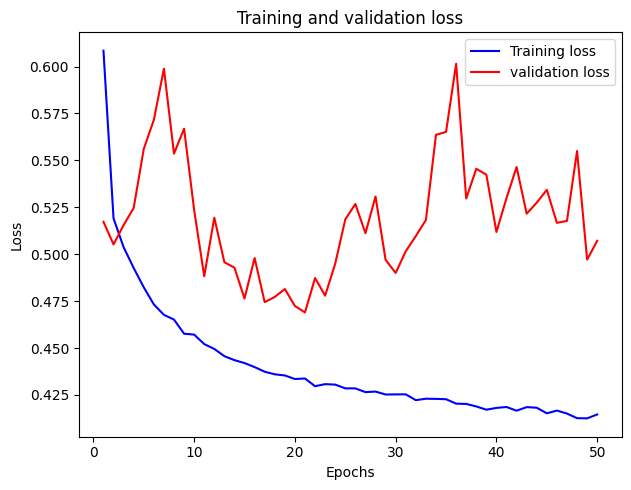

In [27]:
#plot loss curve

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, train_loss , 'b-',label='Training loss')
plt.plot(epochs, val_loss, 'r-',label='validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and validation loss')
plt.legend()
plt.tight_layout()
plt.show();



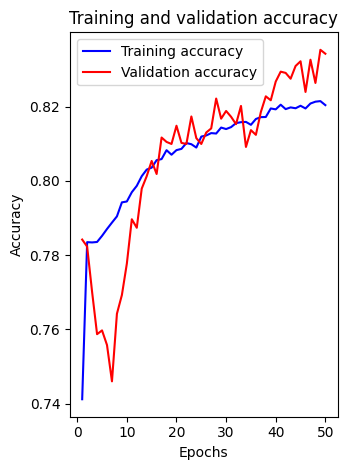

In [28]:
#plot accuracy curve

plt.subplot(1,2,2)
plt.plot(epochs, train_accuracy, 'b-', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'r-',label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.tight_layout()
plt.show();

In [29]:
y_pred_prob = model.predict(x_test) #get pediction probabilities
y_pred = (y_pred_prob > 0.5).astype(int)  #Convert to binary predictions

#Classification report
from sklearn.metrics import classification_report , confusion_matrix
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names = ["Healthy", "Parkinson's"]))



738/738 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
[[ 2021  3072]
 [  843 17680]]
              precision    recall  f1-score   support

     Healthy       0.71      0.40      0.51      5093
 Parkinson's       0.85      0.95      0.90     18523

    accuracy                           0.83     23616
   macro avg       0.78      0.68      0.70     23616
weighted avg       0.82      0.83      0.82     23616



738/738 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


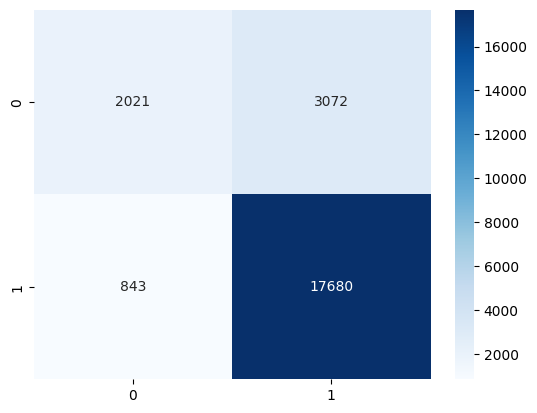

              precision    recall  f1-score   support

     Healthy       0.71      0.40      0.51      5093
 Parkinson's       0.85      0.95      0.90     18523

    accuracy                           0.83     23616
   macro avg       0.78      0.68      0.70     23616
weighted avg       0.82      0.83      0.82     23616



In [30]:
#Confusion Matrix

y_pred = (model.predict([x_test])>0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.show();

#Classification Report
print(classification_report(y_test,y_pred,target_names=["Healthy","Parkinson's"]))
